# 03 — LTspice vs analytical

Created with Grok Build

Batch-runs a generated LTspice `.cir` for Fig. 8-6, compares `.meas`
metrics, and overlays the **full AC Bode** from the LTspice `.raw` file
against the analytical $H_{\mathrm{vin}}(j\omega)$.

**Custom schematic:** export netlist from your `.asc`, keep or rename `.meas`
statements / node names, and call `ltspice_io.run_ltspice_deck` +
`parse_ltspice_raw_ac` (set `vout_name` / `vin_name` to match your nodes).


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Directory that contains opamp_design/. Works when this notebook is run
# from the standalone repo (repo root or notebooks/) or from this website
# section (the folder that holds these notebooks and opamp_design/).
def _find_project_root() -> Path:
    start = Path.cwd().resolve()
    named = Path("Sections/Electronics/Analog_and_Digital/OPA365_Fig86")
    candidates = [start, *start.parents, start / named]
    if start.name == "notebooks":
        candidates.insert(0, start.parent)
    for cand in candidates:
        if (cand / "opamp_design" / "__init__.py").is_file():
            return cand
    return start

ROOT = _find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from opamp_design.params import CircuitParams, OpampParams, ToleranceSpec, format_eng
from opamp_design import analysis, schematic

# -----------------------------------------------------------------------------
# EDITABLE PARAMETERS — change R/C/tolerances here for what-if studies.
# For a completely different netlist, keep these as documentation of the
# stimulus/supply and drive opamp_design.simulate.run_external_netlist(...)
# with your own .cir instead of the Fig. 8-6 generators.
# -----------------------------------------------------------------------------
R1 = 1.8e3       # ohms
R2 = 19.5e3
R3 = 150e3
C1 = 3.3e-9      # farads
C2 = 47e-12
C3 = 220e-12
R_TOL = 0.001    # 0.1% as fraction
C_TOL = 0.01     # 1% as fraction
V_SUPPLY = 5.0
V_IN_BIAS = 2.5
V_IN_PEAK = 2.5
F_DESIGN = 20e3

p = CircuitParams(
    R1=R1, R2=R2, R3=R3, C1=C1, C2=C2, C3=C3,
    r_tol=ToleranceSpec(R_TOL),
    c_tol=ToleranceSpec(C_TOL),
)
# Operating point overrides
from dataclasses import replace
p = replace(p, op=replace(p.op, v_supply=V_SUPPLY, v_in_bias=V_IN_BIAS,
                          v_in_peak=V_IN_PEAK, f_design_hz=F_DESIGN))

FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("ROOT =", ROOT)
print("R1..C3 =", p.passive_dict())


ROOT = .
R1..C3 = {'R1': 1800.0, 'R2': 19500.0, 'R3': 150000.0, 'C1': 3.3e-09, 'C2': 4.7e-11, 'C3': 2.2e-10}


In [2]:
from opamp_design.ltspice_io import find_ltspice, simulate_ltspice_ac_bode
from opamp_design.analysis import summary_metrics, transfer_at_s

print("LTspice:", find_ltspice())
m_an = summary_metrics(p)

wd = ROOT / "results" / "ltspice" / "nom_ideal"
meas = {}
lt_ac = None
try:
    # Returns (.meas scalars, full Bode from .raw)
    meas, lt_ac = simulate_ltspice_ac_bode(
        p, workdir=wd, root=ROOT, opamp_model="ideal"
    )
    print("LTspice meas:", {k: meas[k] for k in meas if k in (
        "gain_100hz", "gain_20k", "phase_20k", "fc_3db", "re_20k", "im_20k"
    )})
    print(
        "LTspice AC points:", len(lt_ac.f_hz),
        "f=[{:.4g}, {:.4g}] Hz".format(lt_ac.f_hz[0], lt_ac.f_hz[-1]),
    )
except Exception as e:
    print("LTspice run failed:", e)
    meas, lt_ac = {}, None

rows = [
    {"source": "analytical", "fc_hz": m_an["fc_hz"],
     "gain_100": m_an["passband_gain"], "gain_20k": m_an["gain_at_fdesign"],
     "phase_20k_deg": m_an["phase_at_fdesign_deg"]},
]
if meas:
    rows.append({
        "source": "LTspice ideal",
        "fc_hz": meas.get("fc_3db", float("nan")),
        "gain_100": meas.get("gain_100hz", float("nan")),
        "gain_20k": meas.get("gain_20k", float("nan")),
        "phase_20k_deg": meas.get("phase_20k", float("nan")),
    })
display(pd.DataFrame(rows))

# Bode error metrics on LTspice frequency grid (should be ~numerical noise for ideal model)
if lt_ac is not None:
    h_a = np.array([
        transfer_at_s(1j * 2 * np.pi * fi, p, "vin") for fi in lt_ac.f_hz
    ])
    err_db = lt_ac.mag_db - 20 * np.log10(np.maximum(np.abs(h_a), 1e-30))
    print(f"max |LTspice - analytical| = {np.max(np.abs(err_db)):.3e} dB")
    print(f"RMS error = {np.sqrt(np.mean(err_db**2)):.3e} dB")


LTspice: LTspice.exe


LTspice meas: {'gain_100hz': 0.9999920840720222, 'gain_20k': 0.7005193945512969, 're_20k': -0.1318489158076977, 'im_20k': -0.6879994807721947, 'fc_3db': 19753.3965864, 'phase_20k': -100.84868672835672}
LTspice AC points: 241 f=[10, 1e+07] Hz


,source,fc_hz,gain_100,gain_20k,phase_20k_deg
0,analytical,19766.713183,0.999993,0.700653,-100.861860
1,LTspice ideal,19753.396586,0.999992,0.700519,-100.848687


max |LTspice - analytical| = 3.365e-04 dB
RMS error = 2.691e-05 dB


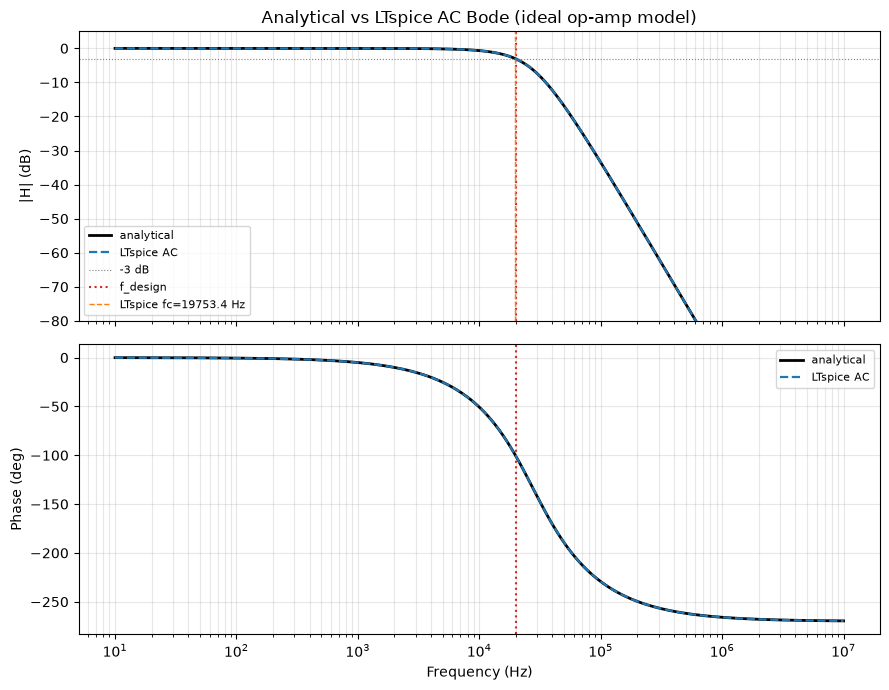

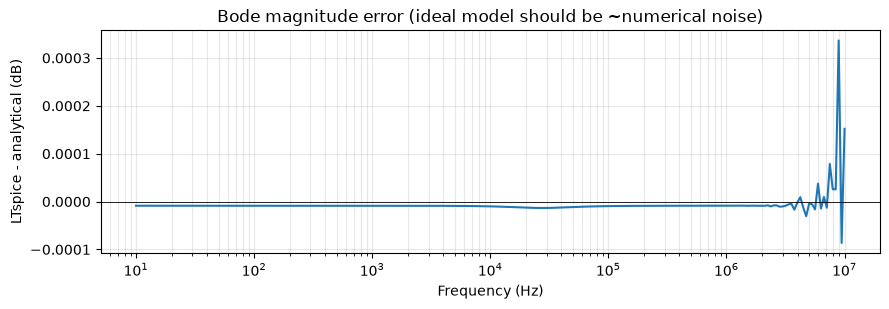

In [3]:
# Overlay analytical H(jw) with full LTspice AC sweep (from .raw)
from opamp_design.analysis import bode

br = bode(p)  # analytical on a dense log grid

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

# --- Magnitude ---
axes[0].semilogx(br.f_hz, br.mag_db, "k-", lw=2.0, label="analytical", zorder=2)
if lt_ac is not None:
    axes[0].semilogx(
        lt_ac.f_hz, lt_ac.mag_db, "C0--", lw=1.6, label="LTspice AC", zorder=3
    )
axes[0].axhline(-3, color="gray", ls=":", lw=0.8, label="-3 dB")
axes[0].axvline(p.op.f_design_hz, color="C3", ls=":", label="f_design")
if meas.get("fc_3db"):
    axes[0].axvline(
        meas["fc_3db"], color="C1", ls="--", lw=1.0,
        label=f"LTspice fc={meas['fc_3db']:.1f} Hz",
    )
axes[0].set_ylabel("|H| (dB)")
axes[0].set_title("Analytical vs LTspice AC Bode (ideal op-amp model)")
axes[0].grid(True, which="both", alpha=0.3)
axes[0].legend(fontsize=8, loc="best")
axes[0].set_ylim(-80, 5)

# --- Phase ---
axes[1].semilogx(
    br.f_hz, br.phase_unwrapped_deg, "k-", lw=2.0, label="analytical", zorder=2
)
if lt_ac is not None:
    axes[1].semilogx(
        lt_ac.f_hz, lt_ac.phase_unwrapped_deg, "C0--", lw=1.6,
        label="LTspice AC", zorder=3,
    )
axes[1].axvline(p.op.f_design_hz, color="C3", ls=":")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Phase (deg)")
axes[1].grid(True, which="both", alpha=0.3)
axes[1].legend(fontsize=8, loc="best")

fig.tight_layout()
fig.savefig(FIG / "03_ltspice_vs_analytical_bode.png", dpi=150)
plt.show()

# Error subplot (LTspice - analytical) when sweep available
if lt_ac is not None:
    h_a = np.array([
        transfer_at_s(1j * 2 * np.pi * fi, p, "vin") for fi in lt_ac.f_hz
    ])
    err_db = lt_ac.mag_db - 20 * np.log10(np.maximum(np.abs(h_a), 1e-30))
    fig, ax = plt.subplots(figsize=(9, 3.2))
    ax.semilogx(lt_ac.f_hz, err_db, color="C0")
    ax.axhline(0, color="k", lw=0.6)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("LTspice - analytical (dB)")
    ax.set_title("Bode magnitude error (ideal model should be ~numerical noise)")
    ax.grid(True, which="both", alpha=0.3)
    fig.tight_layout()
    fig.savefig(FIG / "03_ltspice_error_db.png", dpi=150)
    plt.show()


## Passband transient at 10 kHz

The same 10 kHz, 1 V peak sine about 2.5 V is applied here. Gain and phase are fit on the last 0.5 ms of a 1.5 ms run.

The overlay uses a generated ideal voltage-controlled source, so LTspice and the analytical nodal model are the same linear network. The figure below is `results/figures/Figure_8_6_3_pole_SK_10kHz_tran.png`, exported from `LTSpice/Figure_8_6_3_pole_SK_10kHz_tran.asc` (the AC drawing with the source changed to `SINE(2.5 1 10k)`, for interactive use with the OPA365 symbol).


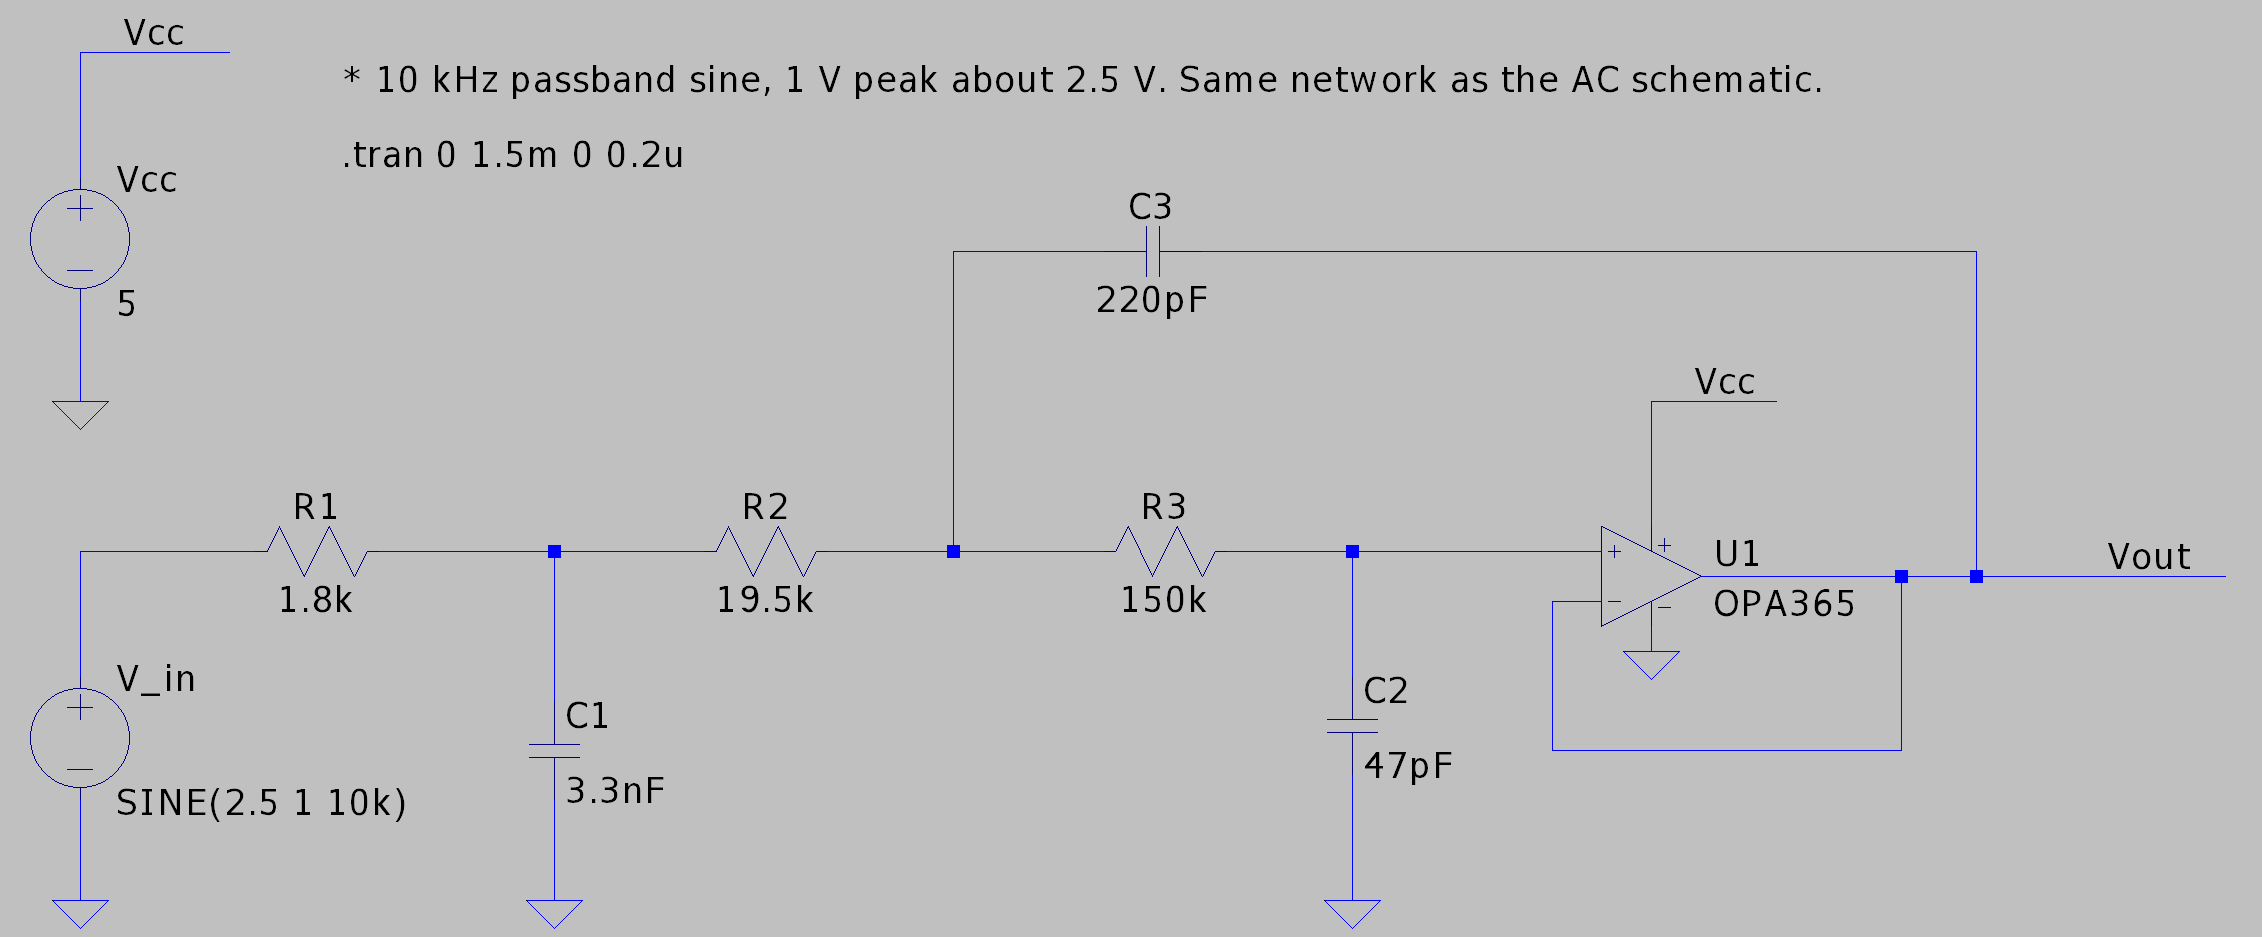

In [10]:
from IPython.display import Image, display

# Exported from LTSpice/Figure_8_6_3_pole_SK_10kHz_tran.asc
spath = FIG / "Figure_8_6_3_pole_SK_10kHz_tran.png"
display(Image(filename=str(spath), width=1100))


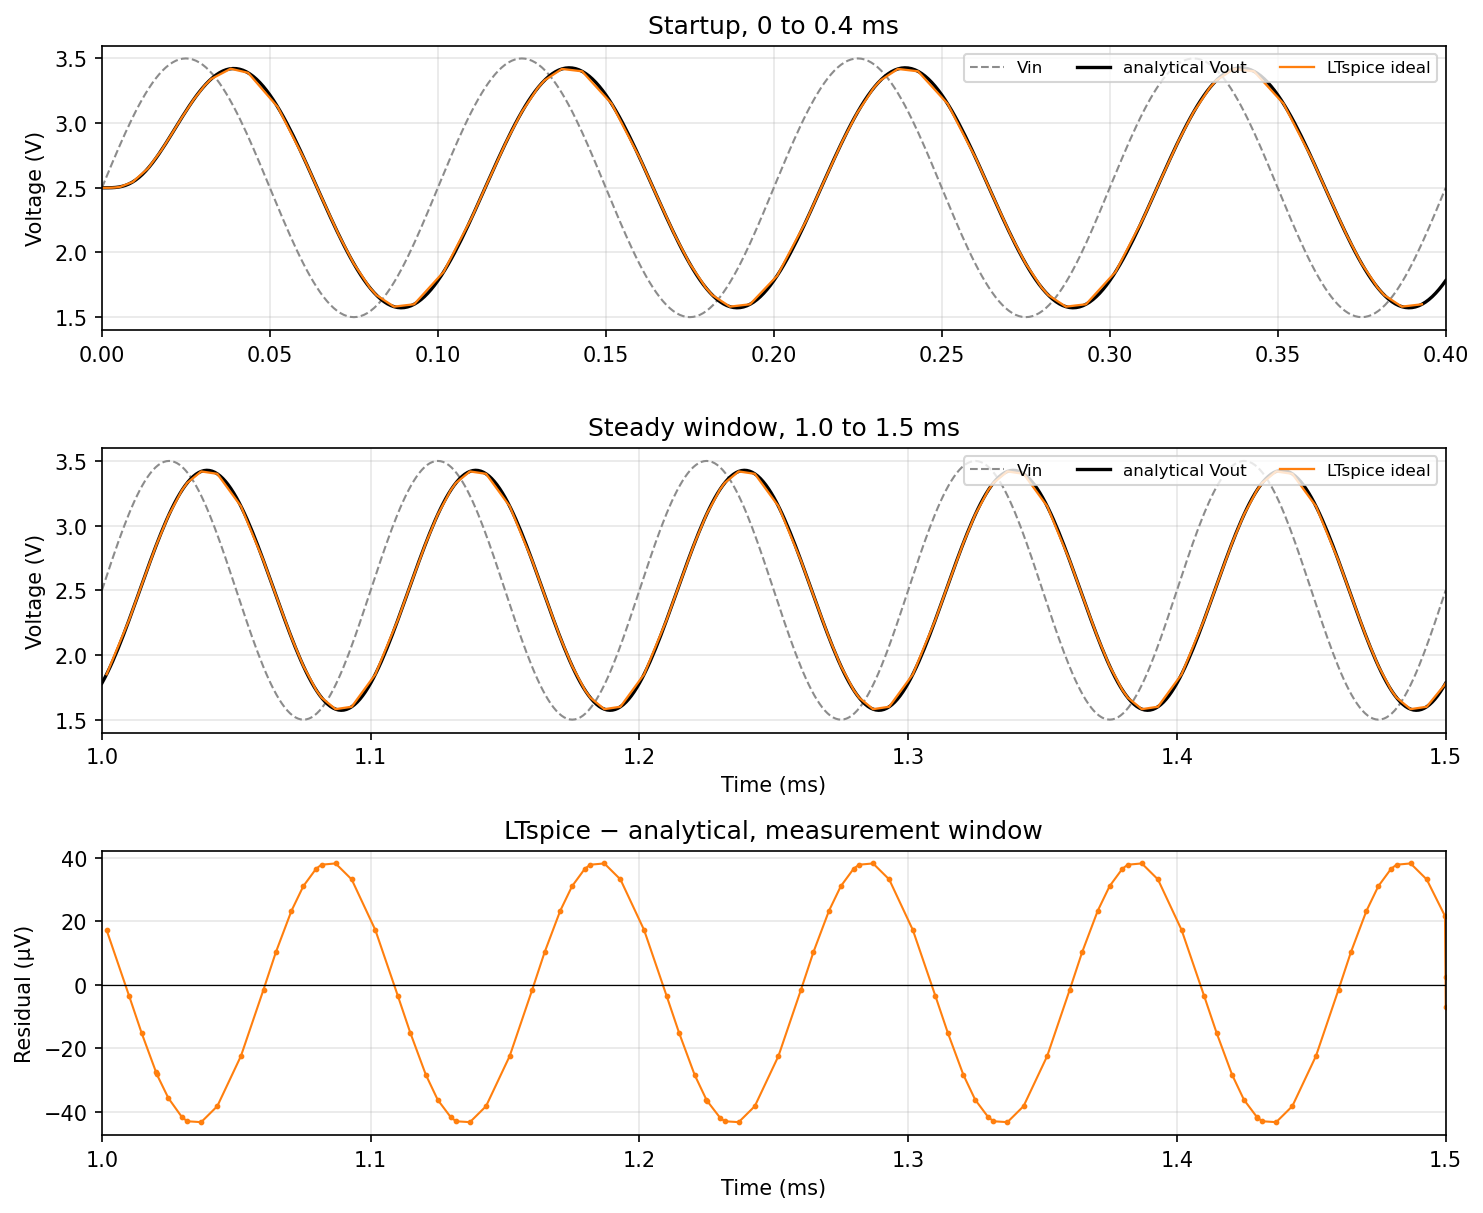

model,gain,phase_deg,gain_error,phase_error_deg
analytical H(jω),0.927440,-50.712,0.000e+00,0.0000
LTspice sine fit,0.927401,-50.713,-3.877e-05,-0.0007
LTspice .four,0.927485,-50.720,4.529e-05,-0.0082


Window residual RMS = 30.57 µV (peak 43.3 µV).
The corner studies use the .four row. The sine fit is the same metric as the waveform plot.


In [11]:
from opamp_design.ltspice_io import parse_ltspice_raw_tran, run_ltspice_deck
from opamp_design.netlist import write_ltspice_tran_deck
from opamp_design.transient import (
    F_PASSBAND_HZ,
    TRAN_AMP_V,
    TRAN_MEAS_FROM_S,
    TRAN_TSTOP_S,
    analytical_tone,
    analytical_waveform,
    measure_tone,
    parse_four_log,
)

freq = F_PASSBAND_HZ
deck = ROOT / "results" / "tran" / "nom_ltspice" / "fig86_tran.cir"
write_ltspice_tran_deck(
    deck,
    p,
    opamp_model="ideal",
    root=ROOT,
    freq_hz=freq,
    amp_v=TRAN_AMP_V,
    tstep_s=2.0e-7,
    tstop_s=TRAN_TSTOP_S,
    tmeas_from_s=TRAN_MEAS_FROM_S,
)
run_ltspice_deck(deck, timeout_s=180)
time, traces = parse_ltspice_raw_tran(deck.with_suffix(".raw"))
vin = np.asarray(traces["v(vin)"], dtype=float)
vout = np.asarray(traces["v(vout)"], dtype=float)
forward = np.concatenate([[True], np.diff(time) > 0])
time, vin, vout = time[forward], vin[forward], vout[forward]
tone_lt = measure_tone(time, vin, vout, freq_hz=freq, t_min=TRAN_MEAS_FROM_S)
tone_four = parse_four_log(deck.with_suffix(".log")).iloc[0]
tone_a = analytical_tone(p, freq_hz=freq, amp_v=TRAN_AMP_V)

t = np.linspace(0.0, TRAN_TSTOP_S, 1501)
vin_a, vout_a = analytical_waveform(p, t, freq_hz=freq, amp_v=TRAN_AMP_V)

fig, axes = plt.subplots(3, 1, figsize=(10, 8.2))
for ax, t0, t1, title in (
    (axes[0], 0.0, 0.4e-3, "Startup, 0 to 0.4 ms"),
    (axes[1], TRAN_MEAS_FROM_S, TRAN_TSTOP_S, "Steady window, 1.0 to 1.5 ms"),
):
    m = (t >= t0) & (t <= t1)
    ml = (time >= t0) & (time <= t1)
    ax.plot(t[m] * 1e3, vin_a[m], color="0.55", lw=1.0, ls="--", label="Vin")
    ax.plot(t[m] * 1e3, vout_a[m], color="k", lw=1.6, label="analytical Vout")
    ax.plot(time[ml] * 1e3, vout[ml], color="C1", lw=1.1, label="LTspice ideal")
    ax.set_xlim(t0 * 1e3, t1 * 1e3)
    ax.set_ylabel("Voltage (V)")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, ncol=3, loc="upper right")
axes[1].set_xlabel("Time (ms)")

# The raw file is plot-compressed. A straight line between saved points is
# not the waveform the solver integrated, so the residual is taken at the
# saved sample times against the analytical solution on that same grid.
_, vout_on_lt = analytical_waveform(p, time, freq_hz=freq, amp_v=TRAN_AMP_V)
ml = (time >= TRAN_MEAS_FROM_S) & (time <= TRAN_TSTOP_S)
resid_uv = (vout[ml] - vout_on_lt[ml]) * 1e6
axes[2].plot(time[ml] * 1e3, resid_uv, color="C1", lw=1.0, marker=".", ms=3.5)
axes[2].axhline(0.0, color="k", lw=0.6)
axes[2].set_xlim(TRAN_MEAS_FROM_S * 1e3, TRAN_TSTOP_S * 1e3)
axes[2].set_xlabel("Time (ms)")
axes[2].set_ylabel("Residual (µV)")
axes[2].set_title("LTspice − analytical, measurement window")
axes[2].grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "03_tran_10khz.png", dpi=150)
plt.show()

rows = [
    ("analytical H(jω)", tone_a.gain, tone_a.phase_deg, 0.0, 0.0),
    ("LTspice sine fit", tone_lt.gain, tone_lt.phase_deg, tone_lt.gain - tone_a.gain, tone_lt.phase_deg - tone_a.phase_deg),
    ("LTspice .four", float(tone_four.gain), float(tone_four.phase_deg), float(tone_four.gain) - tone_a.gain, float(tone_four.phase_deg) - tone_a.phase_deg),
]
show = pd.DataFrame(rows, columns=["model", "gain", "phase_deg", "gain_error", "phase_error_deg"])
show["gain"] = show["gain"].map(lambda v: f"{v:.6f}")
show["phase_deg"] = show["phase_deg"].map(lambda v: f"{v:.3f}")
show["gain_error"] = show["gain_error"].map(lambda v: f"{v:.3e}")
show["phase_error_deg"] = show["phase_error_deg"].map(lambda v: f"{v:.4f}")
display(show)
print(
    f"Window residual RMS = {np.sqrt(np.mean(resid_uv**2)):.2f} µV "
    f"(peak {np.max(np.abs(resid_uv)):.1f} µV)."
)
print("The corner studies use the .four row. The sine fit is the same metric as the waveform plot.")


### Reading the transient

LTspice and the analytical solution overlie each other through startup and in the steady window. The residual, taken at the saved sample times, peaks near 40 µV. The `.four` result, which the worst-case, Monte Carlo, and temperature decks use, agrees with the sine fit of the waveform to about 50 ppm and 0.01°. The schematic above is the macromodel sheet; this comparison is the ideal source, matched to the nodal model.
